<a href="https://colab.research.google.com/github/jesscoe3/MPM_200_Coe/blob/main/Notebooks/261116_assignment_1_will__hummers_survive_JCoe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [ ]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
beep_colab("fanfare")     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Coe!", by = "behindcat")


 _____________________________________ 
< Welcome to Hummingbird HQ, Dr. Coe! >
 ------------------------------------- 
         \
          \

            |\___/|
            )     (
           =\     /=
             )===(
            /     \
            |     |
           /       \
           \       /
      jgs   \__  _/
              ( (
               ) )
              (_(

In [ ]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [ ]:
url <- "/content/Hummingbird_data (1).csv"
data <- read.csv(url)
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `10,000`.
Now find how many rows and columns `data` has.

In [ ]:
# your code here
dim(data)

[1] 6908   12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [ ]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** All columns except for "Brought_in_after" are text (character). Only "Brought_in_after" is a number (integer). Admitted is not stored as a date.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [ ]:
set.seed(0324)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [ ]:
# your code here
dim(model_data)

[1] 5000   12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:** "Brought_in_after" is the only continuous variable. The other 11 columns are categorical. ID is useful for analysis as it is a unique identifier for each bird, helpful for preforming assessments like counts.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [ ]:
write.csv(model_data, "outputs/Hummingbird_data_JessCoe.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [ ]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4124
Santa Barbara,75
malibu,801


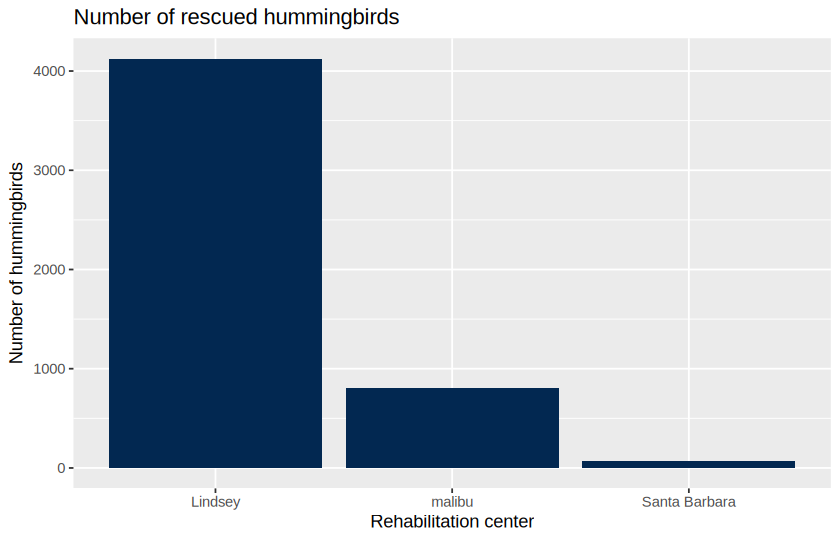

In [ ]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [ ]:
ggsave("outputs/rehab_counts_JessCoe.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**
rehab <- model_data %>% #this line creates a new object called "rehab" using the model_data dataset

  group_by(Place) %>% #this creates three groups out of the data, one for each of the three facilities in the dataset

  summarise(count = n_distinct(ID)) #this counts the number of unique IDs within each of the three groups created above

  p <- ggplot(rehab, aes(x = Place, y = count)) + # this line indicates that we want to create a plot from our data as it is organized in the rehab object; aes assigns our two variables to the x and y axis

  geom_col(fill = "#022851") + #this specifies the type of plot we want to create, a bar chart using a dataset that already includes summary values

  xlab("Rehabilitation center") + #this applies a label to the x axis

  ylab("Number of hummingbirds") + #this applies a label to the y axis

  labs(title = "Number of rescued hummingbirds") #this applies a title to the plot

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:** No - the number of hummingbirds admitted to each facility does not tell us anything about the number of deaths at each facility. While we might be tempted to conclude that, number of birds admitted gives us no information about outcomes.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [ ]:
df <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

df1 <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df1

df2 <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df2

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2098
No,Released,1224
Yes,Died,1085
Yes,Released,593


season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,378
Fall,Released,59
Spring,Died,1332
Spring,Released,964
Summer,Died,912
Summer,Released,616
Winter,Died,561
Winter,Released,178


Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,421
Nestling,Released,776
adult-like,Died,2762
adult-like,Released,1041


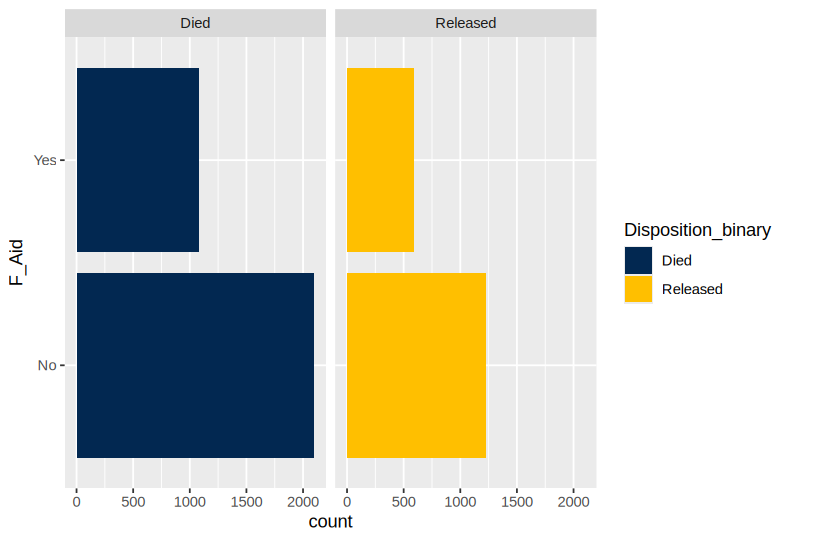

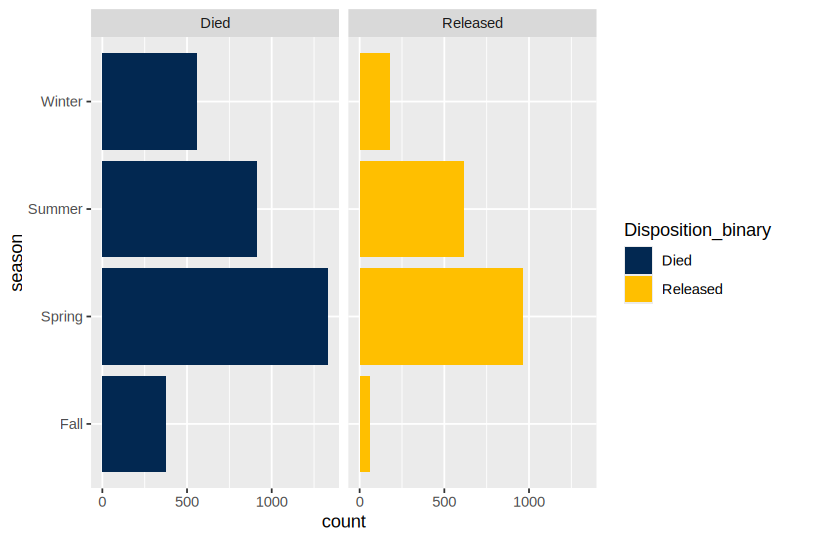

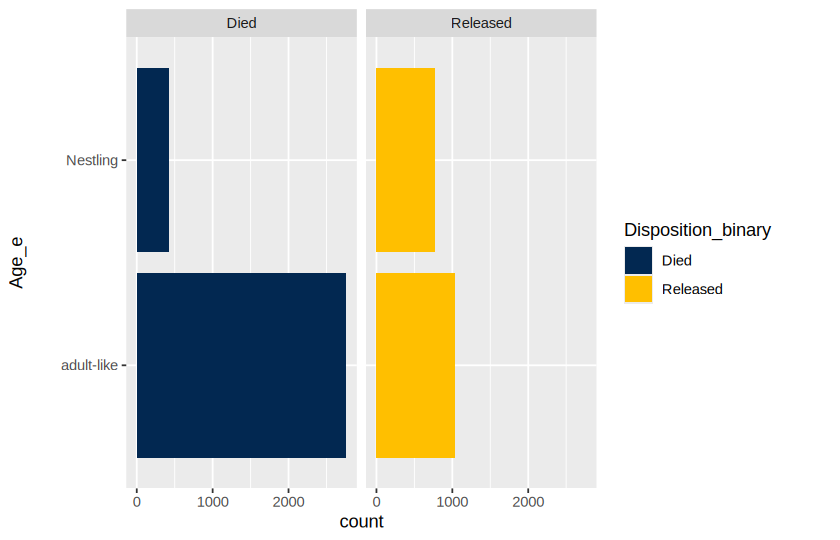

In [ ]:
ggplot(df, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df1, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df2, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:** Season, whether the patient received first aid, and age all appear associated with outcome. Being an adult at time of admission and not receiving first aid appear to be potential risk factors for death. It is more difficult for me to make an assessment about potential risk factors related to seasonality just by looking at the plots. A Chi-squared test of independence could check whether the association is more than chance.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2640,0.6401552
Lindsey,Released,1484,0.3598448
Santa Barbara,Died,43,0.5733333
Santa Barbara,Released,32,0.4266667
malibu,Died,500,0.6242197
malibu,Released,301,0.3757803


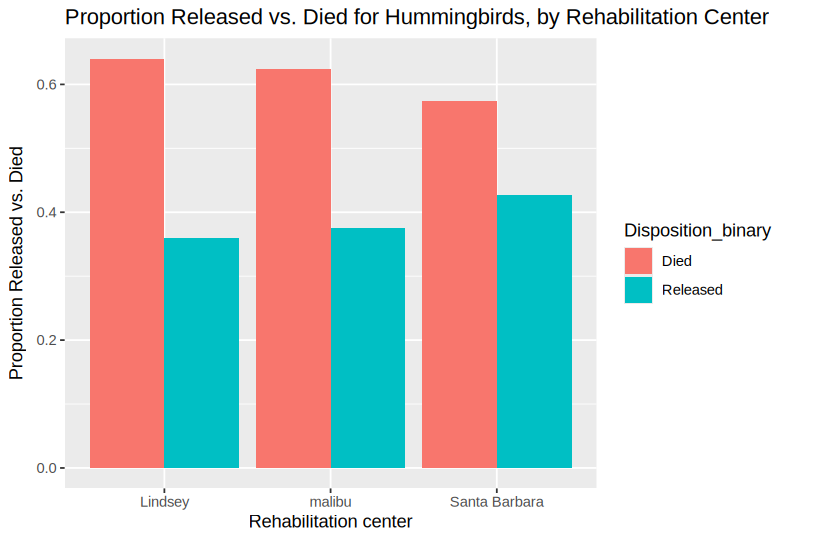

In [ ]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation center") +
  ylab("Proportion Released vs. Died") +
  labs(title = "Proportion Released vs. Died for Hummingbirds, by Rehabilitation Center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4139                0
  Selasphorus                        0              861

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-selasphorus,Died,2638,0.6373520
Non-selasphorus,Released,1501,0.3626480
Selasphorus,Died,545,0.6329849
Selasphorus,Released,316,0.3670151


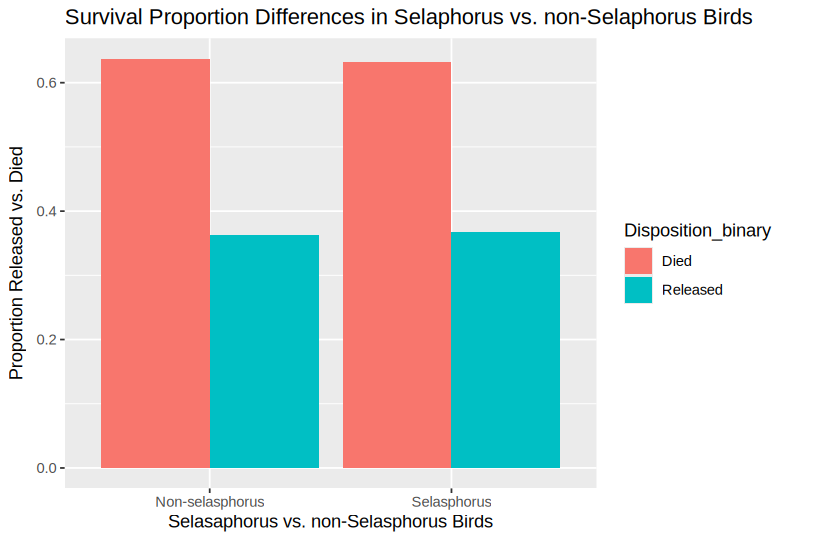

In [ ]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count=n_distinct(ID),.groups = "drop_last") %>%
  mutate(proportion = count / sum(count))
species_distribution

ggplot(species_distribution, aes(x = Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Selasaphorus vs. non-Selasphorus Birds") +
  ylab("Proportion Released vs. Died") +
  labs(title = "Survival Proportion Differences in Selaphorus vs. non-Selaphorus Birds")

✍️ **Your answer:** Survival proportions are very similar between groups, with 36.3% of birds surviving to release in the Non-selasphorous group, and 36.7% of birds surviving to release in the Selasphorous group.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [ ]:
model_data$Admitted <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted)
range(model_data$Admitted)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:** The format argument defines the way that date is formatted in our dataset, with month, followed by day, followed by year. "%d/%m/%Y" would misdefine the format of date in our dataset, and inform R of the incorrect order of day, month, and year, mixing up month and day.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why? Many baby hummingbirds are born in the spring, and are orphaned or injured for various reasons, thus driving up the overall number of hummingbirds admitted to the hospital during this season.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [ ]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count=n_distinct(ID))
admissions_by_month

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count=n_distinct(ID))
admissions_by_year

table(model_data$season)

Admitted_month,count
<chr>,<int>
1991-01,10
1991-02,4
1991-03,23
1991-04,29
1991-05,20
1991-06,24
1991-07,14
1991-08,12
1991-09,6


Admitted_year,count
<chr>,<int>
1991,150
1992,135
1993,134
1994,116
1995,151
1996,147
1997,137
1998,138
1999,142



  Fall Spring Summer Winter 
   437   2296   1528    739 

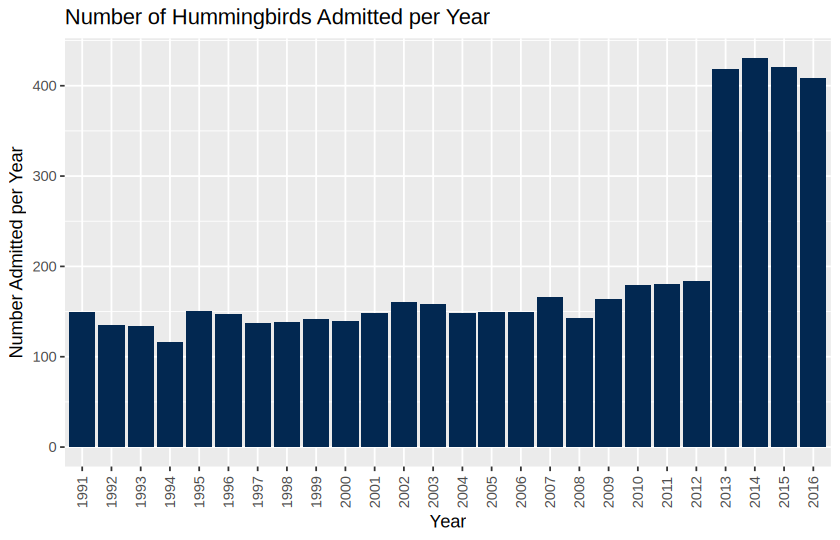

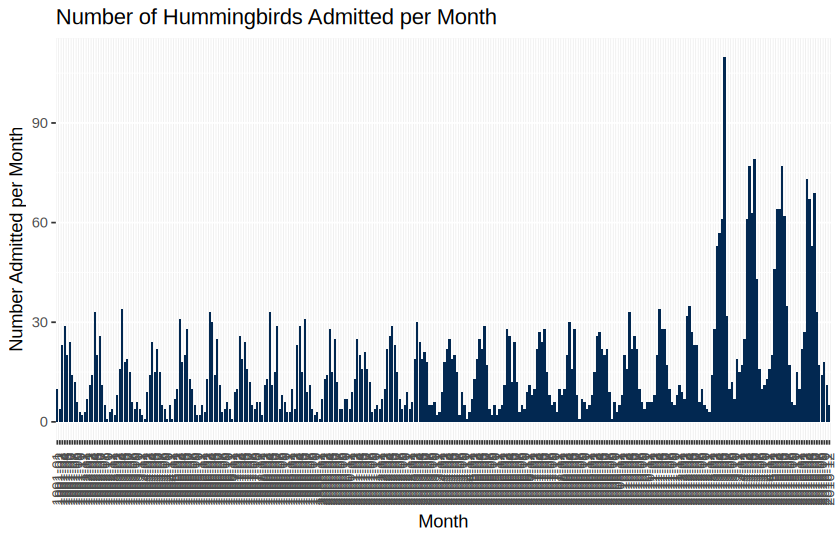

In [ ]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number Admitted per Year") +
  labs(title = "Number of Hummingbirds Admitted per Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number Admitted per Month") +
  labs(title = "Number of Hummingbirds Admitted per Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_month and Species_group.
ℹ Output is grouped by Admitted_month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_month, Species_group))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


Admitted_month,Species_group,count
<chr>,<chr>,<int>
1991-01,Non-selasphorus,10
1991-02,Non-selasphorus,4
1991-03,Non-selasphorus,20
1991-03,Selasphorus,3
1991-04,Non-selasphorus,22
1991-04,Selasphorus,7
1991-05,Non-selasphorus,17
1991-05,Selasphorus,3
1991-06,Non-selasphorus,23


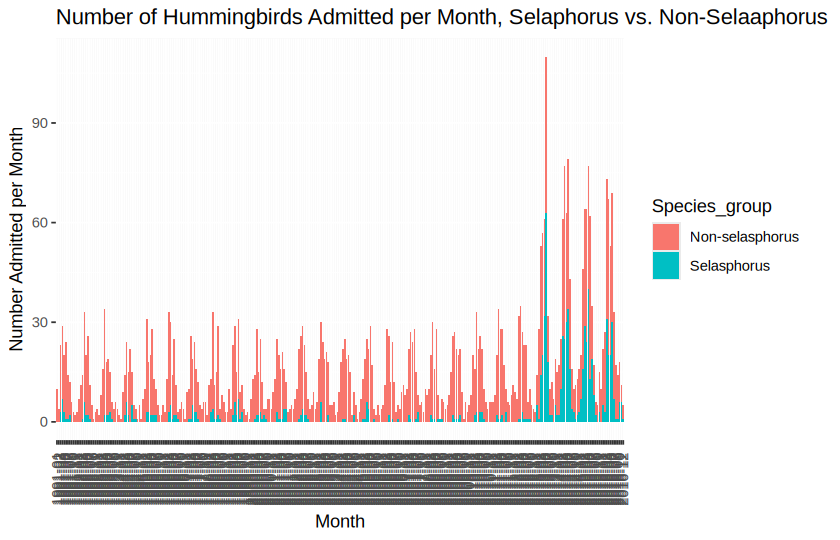

In [ ]:
#This code is for the GitHub assingment
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted, "%Y-%m")) %>%
  group_by(Admitted_month,Species_group) %>%
  summarise(count=n_distinct(ID))
admissions_by_month

ggplot(admissions_by_month, aes(x = Admitted_month, y = count, fill=Species_group)) +
  geom_col() +
  xlab("Month") +
  ylab("Number Admitted per Month") +
  labs(title = "Number of Hummingbirds Admitted per Month, Selaphorus vs. Non-Selaaphorus") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [ ]:
model_data %>% count(Admitted_year = format(Admitted, "%Y"), Place)

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,150
1992,Lindsey,135
1993,Lindsey,134
1994,Lindsey,116
1995,Lindsey,151
1996,Lindsey,147
1997,Lindsey,137
1998,Lindsey,138
1999,Lindsey,142


✍️ **Your answer:** Before 2012, Lindsey was the only hospital reporting data for this dataset. Malibu first reported data in 2012, and Santa Barbara first reported data in 2016. These two new centers contributing reporting is likely the reason for the drastic increase in number of admissions.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [ ]:
# your detective work here
summary(data$Brought_in_after)
unique(data$Sex_e)
unique(data$Place)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -365.000     0.000     0.000     3.058     1.000 16588.000 

[1] "Female-like " "unknown"      "Male"

[1] "Lindsey"       "malibu"        "Santa Barbara"

✍️ **Your answer:** The Brought_in_after variable has many large, negative values that we cannot intepret. If analyzing this variable, I would filter the .csv file to only include records with values greater than or equal to 0. The Sex_e variable category "Female-like" includes a space after the text, which would lead to issues in analysis (i.e. R would not recognize this character unless the space were included in code writing). I would find and replace all instances of "Female-like" with the space removed in the .csv file. The facility name, "malibu" is not capitalized, which could lead to issues in coding since R is very sensiive to case. I would find and replace all instances of "malibu" with "Malibu" in the .csv file.  

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:** It surprised me that the survival proportion was almost exactly the same between Selaphorous and non-Selaphorous species. One error that I hit was stacked rather than side-by-side bars, and I fixed it with geom_col(position = "dodge").

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄

# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [ ]:
fullmodel  = glm(__________ ~ r + Green_Orange + season+F_Aid+Species_e, data = _______, family= binomial(link = logit))
fullmodel

2. use following command with full model to do stepwise model selection

In [ ]:
backward_model = step(__________,k=2,direction = "backward",test="Chisq")

In [ ]:
forward_model = step(___________,k=2,direction = ,test="Chisq")

### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [ ]:
names(backward_model)

explore individual attributes of the fitted model and read about it in the R documentation

In [ ]:
library(sjPlot)

In [ ]:
tab_model(backward_model)